# Multi-organ segmentation of OrganDataProcessed
### Class example · data → 2D U-Net → evaluation → plots

We train one network that labels **every voxel** as background or one of **8 pelvic organs**, using the preprocessed data from `organdata_preprocessing.ipynb`
(all scans at 1 × 1 × 2 mm and 192 × 192 × 48 voxels).

```
OrganDataProcessed/ (17 patients)
  → 1. load, normalise intensities, look at the data
  → 2. split by PATIENT: train / val / test
  → 3. 2D axial slices, Dataset + augmentation (MONAI)
  → 4. 2D U-Net with 9 output channels (background + 8 organs), Dice + cross-entropy loss
  → 5. train, validate on whole volumes, keep the best model
  → 6. evaluate on the test patients: Dice, HD95 (mm), volume error, per organ
  → 7. plots: boxplots, volume agreement, confusion matrix, overlays
  → 8. save predictions as NIfTI
```

**Multi-class vs binary.** A binary network answers "organ or not?" with one output and a sigmoid.
Here the network has **9 outputs per pixel** (one score per class); **softmax** turns them into probabilities that sum to 1, and **argmax** picks the class.

In [1]:
# Run once if needed (then restart the kernel)
# %pip install torch monai SimpleITK scipy scikit-learn pandas matplotlib

## 0 · Setup and settings

In [2]:
import random, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import SimpleITK as sitk
from scipy import ndimage
from sklearn import metrics
import torch
from torch.utils.data import Dataset, DataLoader
from monai.networks.nets import UNet
from monai.losses import DiceCELoss
from monai.transforms import Compose, RandFlipd, RandRotated, RandScaleIntensityd, RandShiftIntensityd, EnsureTyped
from monai.utils import set_determinism

SEED = 0
set_determinism(SEED); random.seed(SEED); np.random.seed(SEED)
DEVICE = ("cuda" if torch.cuda.is_available()
          else "mps" if torch.backends.mps.is_available()     # Apple silicon GPU
          else "cpu")
print("torch", torch.__version__, "| device:", DEVICE)

# ----------------------------- data -----------------------------
DATA_DIR = Path("../../OrganDataProcessed")      # relative to this notebook (scripts/)
OUT_DIR  = Path("seg_outputs")
OUT_DIR.mkdir(exist_ok=True)
N_CLASSES = 9                                 # background + organs 1-8
ORGANS = {k: f"organ {k}" for k in range(1, N_CLASSES)}   # replace with real names if you know them
COLOURS = plt.cm.tab10(np.arange(10))         # organ k is always drawn in COLOURS[k]

# --------------------------- training ---------------------------
N_VAL, N_TEST = 3, 4                          # patients; the remaining 10 train
EPOCHS     = 40
BATCH_SIZE = 16
LR         = 1e-3
KEEP_EMPTY = 0.2                              # fraction of slices without any organ kept for training

<python-environment>/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
<python-environment>/lib/python3.10/site-packages/transformers/utils/generic.py:441: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(
<python-environment>/lib/python3.10/site-packages/transformers/utils/generic.py:309: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(


torch 2.6.0 | device: mps


## 1 · Load the data

All volumes are on the same grid, so we can load them straight into arrays of shape `(z, y, x) = (48, 192, 192)`.

**Intensity normalisation.** MR intensities have no fixed units (some scans 0–1, some 0–2000).
Per volume we clip the extreme 0.5% (bright artefacts) and rescale to zero mean and unit standard deviation, so every scan reaches the network in the same range.

In [3]:
def normalise(arr):
    lo, hi = np.percentile(arr, [0.5, 99.5])
    arr = np.clip(arr, lo, hi)
    return ((arr - arr.mean()) / (arr.std() + 1e-8)).astype(np.float32)

cases = []
for img_path in sorted(DATA_DIR.glob("*_img.nii*")):
    mask_path = img_path.with_name(img_path.name.replace("_img", "_mask"))
    img = sitk.ReadImage(str(img_path), sitk.sitkFloat32)
    mask = sitk.ReadImage(str(mask_path), sitk.sitkUInt8)
    cases.append({"name": img_path.name.split("_")[0], "sitk": img,
                  "img": normalise(sitk.GetArrayFromImage(img)), "lab": sitk.GetArrayFromImage(mask)})

SPACING_ZYX = cases[0]["sitk"].GetSpacing()[::-1]   # numpy order (z, y, x) = (2, 1, 1) mm
VOXEL_ML = np.prod(SPACING_ZYX) / 1000
print(f"{len(cases)} patients, volume shape {cases[0]['img'].shape} (z, y, x), spacing {SPACING_ZYX} mm")

print("Organ volumes (ml):")
pd.DataFrame([{"patient": c["name"], **{ORGANS[k]: round((c["lab"] == k).sum() * VOXEL_ML, 1) for k in ORGANS}}
              for c in cases]).set_index("patient")

17 patients, volume shape (48, 192, 192) (z, y, x), spacing (2.0, 1.0, 1.0) mm
Organ volumes (ml):


,organ 1,organ 2,organ 3,organ 4,organ 5,organ 6,organ 7,organ 8
patient,,,,,,,,
001000,28.5,59.6,90.6,28.5,19.6,70.2,8.0,5.8
001001,58.2,84.4,81.4,16.0,17.3,77.2,24.8,3.7
001002,30.8,39.2,63.8,26.3,15.9,50.8,12.0,2.4
001003,145.5,60.2,78.1,21.6,9.4,28.8,19.8,6.5
001004,42.5,59.6,106.1,21.2,10.0,30.7,10.2,3.6
001005,36.7,44.5,73.2,23.9,18.4,36.0,4.9,6.7
001006,69.2,81.9,71.5,16.3,11.0,35.0,19.5,9.3
002000,44.4,78.0,69.8,20.7,17.1,44.4,17.6,5.7
002002,69.3,64.2,60.8,26.8,37.8,34.1,18.9,5.8


The organs differ a lot in size (from a few ml to over 100 ml). Expect the **small organs** to be harder, and Dice to punish them more for the same boundary error.

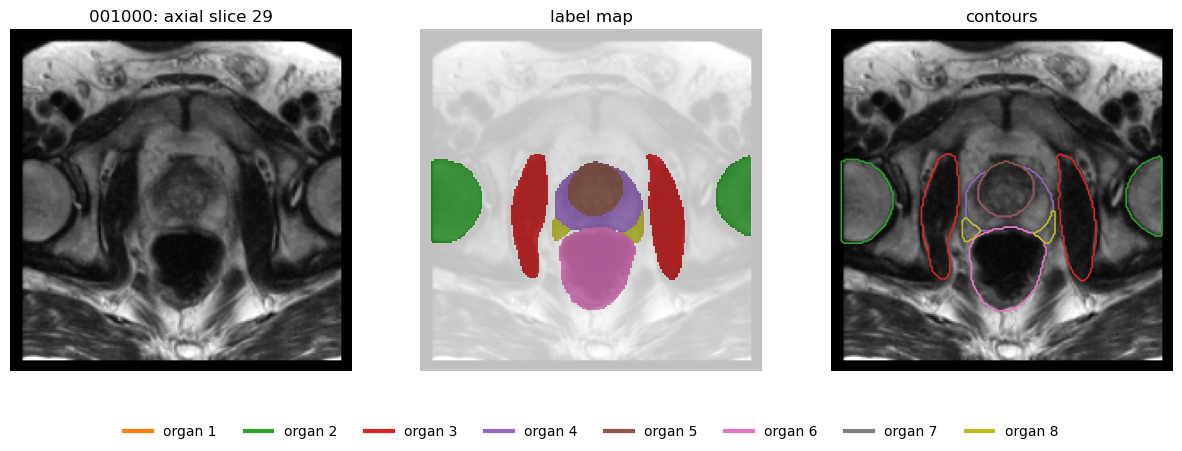

In [4]:
def draw_labels(ax, lab2d, lw=1.2, ls="-"):
    # one contour per organ, in that organ's fixed colour
    for k in np.unique(lab2d[lab2d > 0]):
        ax.contour(lab2d == k, levels=[0.5], colors=[COLOURS[k]], linewidths=lw, linestyles=ls)

c = cases[0]
k = int((c["lab"] > 0).sum(axis=(1, 2)).argmax())                # slice with the most organ voxels
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(c["img"][k], cmap="gray"); axes[0].set_title(f'{c["name"]}: axial slice {k}')
axes[1].imshow(np.ma.masked_equal(c["lab"][k], 0), cmap="tab10", vmin=0, vmax=9, interpolation="nearest")
axes[1].imshow(c["img"][k], cmap="gray", alpha=0.25); axes[1].set_title("label map")
axes[2].imshow(c["img"][k], cmap="gray"); draw_labels(axes[2], c["lab"][k]); axes[2].set_title("contours")
for ax in axes: ax.axis("off")
handles = [plt.Line2D([], [], color=COLOURS[k], lw=3, label=ORGANS[k]) for k in ORGANS]
fig.legend(handles=handles, loc="lower center", ncol=8, frameon=False)
plt.show()

## 2 · Split by patient

Neighbouring slices of one scan are almost identical. If slices of one patient were in both train and test, the test score would be **inflated** (leakage).
So we split **patients** first, and cut volumes into slices afterwards.
* **train**: the network learns from these;
* **val**: used during training to pick the best epoch (and any setting we tune);
* **test**: used **once**, at the end, to report results.

In [5]:
order = np.random.default_rng(SEED).permutation(len(cases))
test_cases  = [cases[i] for i in order[:N_TEST]]
val_cases   = [cases[i] for i in order[N_TEST:N_TEST + N_VAL]]
train_cases = [cases[i] for i in order[N_TEST + N_VAL:]]
for name, part in [("train", train_cases), ("val", val_cases), ("test", test_cases)]:
    print(f"{name:5s}: {len(part):2d} patients  {[c['name'] for c in part]}")

train: 10 patients  ['001005', '002010', '002006', '002007', '001006', '002003', '002008', '002002', '001001', '002009']
val  :  3 patients  ['001000', '001004', '002000']
test :  4 patients  ['001002', '002004', '001003', '002005']


## 3 · Slices, Dataset and augmentation

* A **2D** U-Net works on one axial slice at a time: fast, light on memory, and 10 patients give ~400 training images.
* We keep every slice that contains an organ, plus `KEEP_EMPTY` of the empty ones (top and bottom of the scan).
* **Augmentation** (training only), with [MONAI](https://monai.io) dictionary transforms so image and label move together:
  left-right flip, small rotations (label with **nearest** interpolation so it stays integer), and small intensity changes (image only).
  Left-right flipping is safe here because paired organs share one label.

In [6]:
def to_slices(case_list, keep_empty=1.0, seed=SEED):
    rng = np.random.default_rng(seed)
    X, Y = [], []
    for c in case_list:
        for k in range(c["img"].shape[0]):
            if c["lab"][k].any() or rng.random() < keep_empty:
                X.append(c["img"][k]); Y.append(c["lab"][k])
    return np.stack(X), np.stack(Y)

class SliceDataset(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images, self.labels, self.transform = images, labels, transform
    def __len__(self):
        return len(self.images)
    def __getitem__(self, i):
        sample = {"image": self.images[i][None],                       # (1, H, W): channel first
                  "label": self.labels[i][None].astype(np.float32)}    # class index 0-8 per pixel
        return self.transform(sample) if self.transform else sample

keys = ["image", "label"]
train_tf = Compose([
    RandFlipd(keys, prob=0.5, spatial_axis=1),                                   # left-right
    RandRotated(keys, range_x=0.2, prob=0.5, mode=("bilinear", "nearest")),      # +/- 11 degrees
    RandScaleIntensityd("image", factors=0.1, prob=0.5),
    RandShiftIntensityd("image", offsets=0.1, prob=0.5),
    EnsureTyped(keys, track_meta=False),
])
train_tf.set_random_state(seed=SEED)

Xtr, Ytr = to_slices(train_cases, keep_empty=KEEP_EMPTY)
train_ds = SliceDataset(Xtr, Ytr, transform=train_tf)
g = torch.Generator(); g.manual_seed(SEED)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, generator=g)
print(f"training slices: {len(train_ds)} from {len(train_cases)} patients")

batch = next(iter(train_loader))
print("batch:", tuple(batch["image"].shape), tuple(batch["label"].shape), "| label values:", batch["label"].unique().int().tolist())

training slices: 425 from 10 patients
batch: (16, 1, 192, 192) (16, 1, 192, 192) | label values: [0, 1, 2, 3, 4, 5, 6, 7, 8]


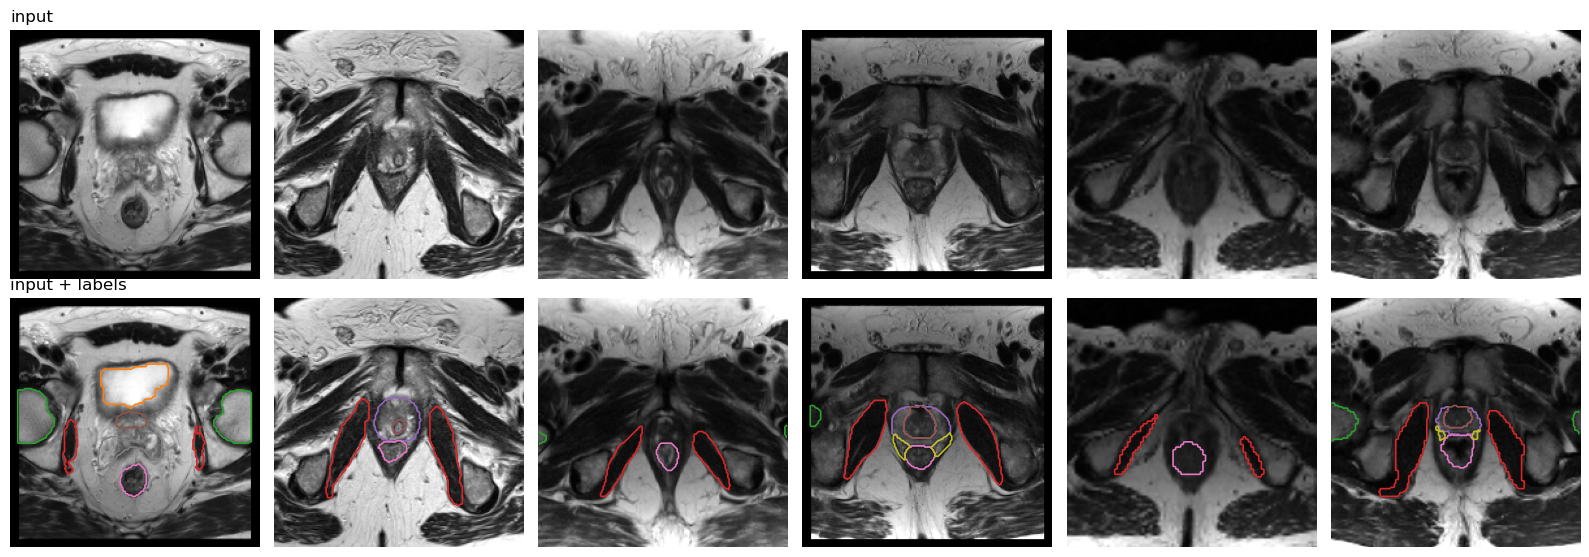

In [7]:
# What the network sees: augmented training slices with their labels
fig, axes = plt.subplots(2, 6, figsize=(16, 5.6))
for n in range(6):
    s = train_ds[random.randrange(len(train_ds))]
    axes[0, n].imshow(s["image"][0], cmap="gray")
    axes[1, n].imshow(s["image"][0], cmap="gray"); draw_labels(axes[1, n], s["label"][0].numpy().astype(int))
for ax in axes.ravel(): ax.axis("off")
axes[0, 0].set_title("input", loc="left"); axes[1, 0].set_title("input + labels", loc="left")
plt.tight_layout(); plt.show()

## 4 · Model and loss

**U-Net** (MONAI): an encoder that shrinks the image to learn *what* is there, a decoder that grows it back, and skip connections that tell the decoder *where* the edges are.
* `out_channels=9`: one score map per class.
* `channels=(16, 32, 64, 128, 256)`, `strides=(2, 2, 2, 2)`: 4 downsamplings, 192 → 12 pixels at the bottom; `num_res_units=2` adds residual connections.

**Loss: Dice + cross-entropy** (`DiceCELoss`).
* **Cross-entropy** scores every pixel: stable gradients, but dominated by the (huge) background.
* **Dice** scores overlap per class: every organ counts, however small.
* `to_onehot_y=True`: the label is a class-index map, the loss converts it to 9 binary maps; `softmax=True`: the network outputs raw scores.

In [8]:
model = UNet(spatial_dims=2, in_channels=1, out_channels=N_CLASSES,
             channels=(16, 32, 64, 128, 256), strides=(2, 2, 2, 2), num_res_units=2).to(DEVICE)
loss_fn = DiceCELoss(to_onehot_y=True, softmax=True)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)   # LR decays smoothly to 0
print(f"U-Net with {sum(p.numel() for p in model.parameters()) / 1e6:.2f} M parameters")
with torch.no_grad():
    print("output for one batch:", tuple(model(batch["image"].to(DEVICE)).shape), "= (batch, classes, H, W)")

U-Net with 1.63 M parameters
output for one batch: (16, 9, 192, 192) = (batch, classes, H, W)


## 5 · Training

Each epoch:
1. **train** on all training slices (with augmentation);
2. **validate** like real use: predict **every slice** of each validation patient, stack into a 3D volume, and compute the **3D Dice** of each organ;
3. keep the weights with the best mean validation Dice. That is the model we test.

Below are the evaluation helpers we also use on the test set.

In [ ]:
@torch.no_grad()
def predict_volume(model, vol, batch=16):
    # vol: normalised (z, y, x) -> class probabilities (C, z, y, x)
    model.eval()
    probs = []
    for s in range(0, len(vol), batch):
        x = torch.from_numpy(vol[s:s + batch][:, None]).to(DEVICE)    # (b, 1, H, W)
        probs.append(torch.softmax(model(x), dim=1).cpu())
    return torch.cat(probs).permute(1, 0, 2, 3).numpy()                 # (C, z, y, x)

def dice(a, b):
    # Dice of two binary arrays; nan if the organ is absent in both
    a, b = a.astype(bool), b.astype(bool)
    s = a.sum() + b.sum()
    return np.nan if s == 0 else 2 * (a & b).sum() / s

def per_organ_dice(pred, gt):
    return {k: dice(pred == k, gt == k) for k in ORGANS}

history = {"train_loss": [], "val_dice": [], "val_dice_per_organ": []}
best_dice, best_path = -1, OUT_DIR / "best_unet.pt"P

In [10]:
for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    model.train()
    losses = []
    for batch in train_loader:
        x, y = batch["image"].to(DEVICE), batch["label"].to(DEVICE)
        optimizer.zero_grad()
        loss = loss_fn(model(x), y)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    scheduler.step()

    # validation on whole volumes
    per_organ = pd.DataFrame([per_organ_dice(predict_volume(model, c["img"]).argmax(0), c["lab"]) for c in val_cases])
    val_dice = per_organ.mean().mean()                       # mean over organs of the mean over patients
    history["train_loss"].append(np.mean(losses))
    history["val_dice"].append(val_dice)
    history["val_dice_per_organ"].append(per_organ.mean())

    flag = ""
    if val_dice > best_dice:
        best_dice = val_dice
        torch.save(model.state_dict(), best_path)
        flag = "  <- best, saved"
    print(f"epoch {epoch:3d} | train loss {history['train_loss'][-1]:.3f} | val Dice {val_dice:.3f} | {time.time() - t0:4.1f}s{flag}")

print(f"\nBest mean val Dice: {best_dice:.3f}")

epoch   1 | train loss 2.584 | val Dice 0.134 |  3.3s  <- best, saved
epoch   2 | train loss 1.602 | val Dice 0.183 |  2.1s  <- best, saved
epoch   3 | train loss 1.206 | val Dice 0.244 |  2.2s  <- best, saved
epoch   4 | train loss 1.036 | val Dice 0.295 |  2.1s  <- best, saved
epoch   5 | train loss 0.914 | val Dice 0.368 |  2.1s  <- best, saved
epoch   6 | train loss 0.822 | val Dice 0.391 |  2.1s  <- best, saved
epoch   7 | train loss 0.771 | val Dice 0.463 |  2.1s  <- best, saved
epoch   8 | train loss 0.732 | val Dice 0.510 |  2.1s  <- best, saved
epoch   9 | train loss 0.700 | val Dice 0.535 |  2.1s  <- best, saved
epoch  10 | train loss 0.663 | val Dice 0.557 |  2.8s  <- best, saved
epoch  11 | train loss 0.626 | val Dice 0.565 |  3.6s  <- best, saved
epoch  12 | train loss 0.608 | val Dice 0.571 |  3.8s  <- best, saved
epoch  13 | train loss 0.589 | val Dice 0.582 |  3.7s  <- best, saved
epoch  14 | train loss 0.577 | val Dice 0.601 |  3.7s  <- best, saved
epoch  15 | train lo

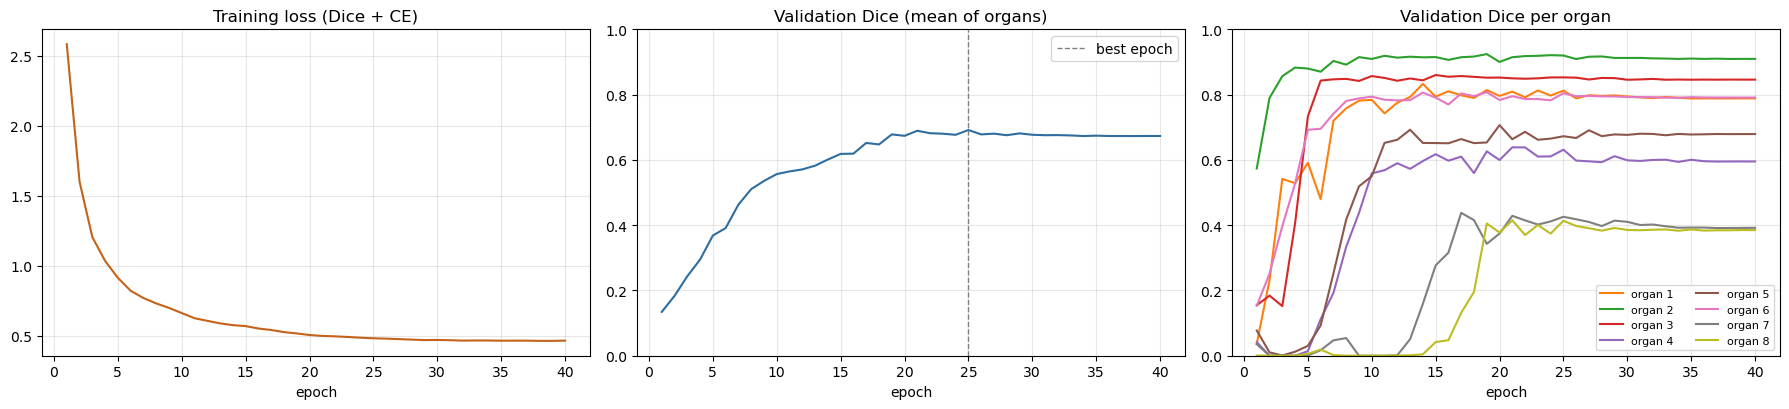

In [11]:
ep = np.arange(1, len(history["train_loss"]) + 1)
per_organ_curves = pd.DataFrame(history["val_dice_per_organ"], index=ep)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.2))
axes[0].plot(ep, history["train_loss"], color="#c4621a")
axes[0].set_title("Training loss (Dice + CE)"); axes[0].set_xlabel("epoch")
axes[1].plot(ep, history["val_dice"], color="#2f6d9e")
axes[1].axvline(ep[int(np.argmax(history["val_dice"]))], color="grey", ls="--", lw=1, label="best epoch")
axes[1].set_title("Validation Dice (mean of organs)"); axes[1].set_xlabel("epoch"); axes[1].set_ylim(0, 1); axes[1].legend()
for k in ORGANS:
    axes[2].plot(ep, per_organ_curves[k], color=COLOURS[k], label=ORGANS[k])
axes[2].set_title("Validation Dice per organ"); axes[2].set_xlabel("epoch"); axes[2].set_ylim(0, 1)
axes[2].legend(fontsize=8, ncol=2)
for ax in axes: ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Reading the curves.** The loss should go down and the validation Dice up, then level off. Large organs are learned first; small ones later, and less well.
The learning rate follows a cosine schedule down to 0, so the curves flatten at the end by design. If the small organs were still improving when it flattened, try more `EPOCHS`.
If the training loss kept falling while validation Dice dropped, the model would be **overfitting**: more data, more augmentation or fewer epochs would help.

## 6 · Evaluate on the test patients

We load the **best** weights and predict each test patient as a whole volume. Per patient and per organ we report:

| metric | what it measures | best |
|---|---|---|
| **Dice** | overlap, 2\|A∩B\| / (\|A\|+\|B\|) | 1 |
| **HD95** (mm) | 95th percentile of the boundary distances: "how far off is the outline", robust to a few stray voxels | 0 |
| **volume error** (ml) | predicted − true volume: what a clinician might measure | 0 |

Distances use the voxel spacing (2 mm between slices, 1 mm in-plane), so they are in **mm**, not voxels.

In [12]:
def surface(m):
    return m & ~ndimage.binary_erosion(m)

def hd95(a, b, spacing=SPACING_ZYX):
    # symmetric 95th-percentile surface distance in mm; nan if either mask is empty
    a, b = a.astype(bool), b.astype(bool)
    if not a.any() or not b.any():
        return np.nan
    d_ab = ndimage.distance_transform_edt(~surface(b), sampling=spacing)[surface(a)]
    d_ba = ndimage.distance_transform_edt(~surface(a), sampling=spacing)[surface(b)]
    return max(np.percentile(d_ab, 95), np.percentile(d_ba, 95))

model.load_state_dict(torch.load(best_path, map_location=DEVICE))
rows = []
for c in test_cases:
    c["prob"] = predict_volume(model, c["img"])
    c["pred"] = c["prob"].argmax(0).astype(np.uint8)
    for k, organ in ORGANS.items():
        gt, pr = c["lab"] == k, c["pred"] == k
        rows.append({"patient": c["name"], "organ": organ,
                     "Dice": dice(pr, gt), "HD95 (mm)": hd95(pr, gt),
                     "true ml": gt.sum() * VOXEL_ML, "pred ml": pr.sum() * VOXEL_ML})
results = pd.DataFrame(rows)
results["volume error (ml)"] = results["pred ml"] - results["true ml"]
results.to_csv(OUT_DIR / "test_results.csv", index=False)

summary = results.groupby("organ", sort=False)[["Dice", "HD95 (mm)", "volume error (ml)"]].agg(["mean", "std"])
summary.loc["ALL ORGANS"] = results[["Dice", "HD95 (mm)", "volume error (ml)"]].agg(["mean", "std"]).T.stack()
summary.round(2)

Dice       HD95 (mm)        volume error (ml)       
            mean   std      mean    std              mean    std
organ                                                           
organ 1     0.53  0.28     20.49   9.78            -31.93  32.67
organ 2     0.89  0.03     20.67  19.47             -6.05   6.91
organ 3     0.83  0.04     17.74  17.08             -3.60   3.18
organ 4     0.36  0.11     10.61   1.69             -7.95   3.35
organ 5     0.62  0.04     16.66   8.89             -2.66   7.72
organ 6     0.77  0.07     38.63  40.72             -1.74  10.90
organ 7     0.19  0.13     19.01   8.82            -11.02   5.26
organ 8     0.28  0.16     25.04   7.79             -2.85   2.70
ALL ORGANS  0.56  0.28     21.11  17.79             -8.48  14.85

Report **mean ± std** over patients, per organ. With only 4 test patients, the std is large and one bad case moves the mean a lot: a reminder that small test sets give uncertain numbers.

The full table (one row per patient and organ) is saved in `seg_outputs/test_results.csv`.

## 7 · Plots

### 7a · Metric distribution per organ
One dot per test patient. Boxplots show the median and spread at a glance; the dots stop us hiding that n = 4.

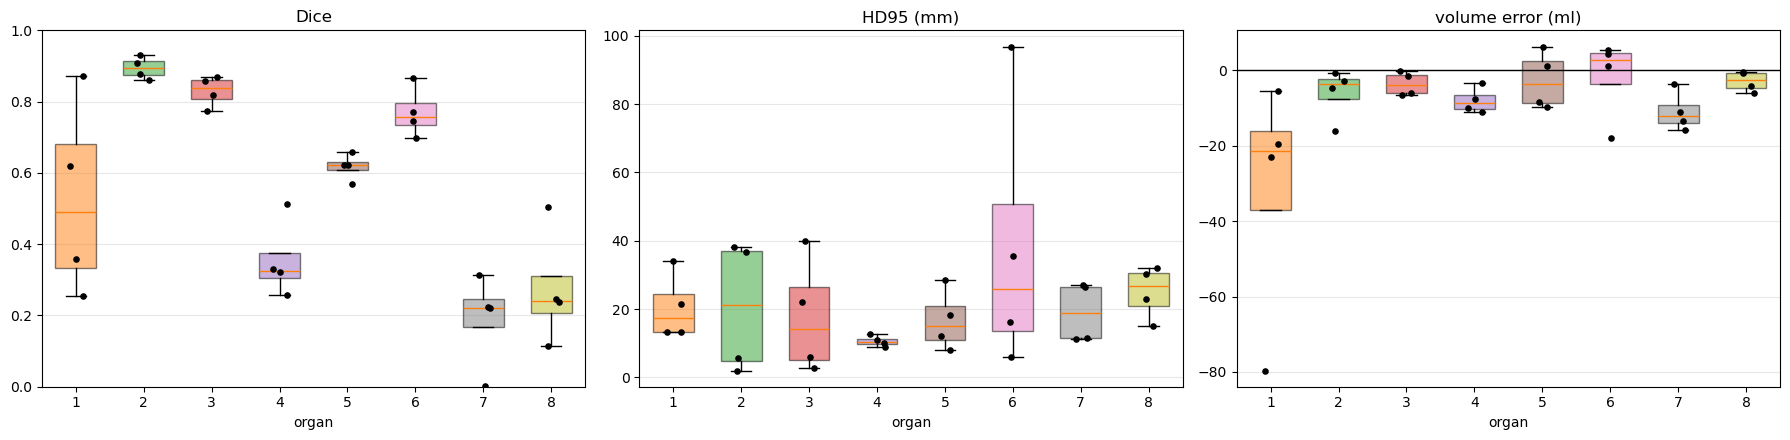

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, col in zip(axes, ["Dice", "HD95 (mm)", "volume error (ml)"]):
    data = [results.loc[results.organ == o, col].dropna() for o in ORGANS.values()]
    bp = ax.boxplot(data, patch_artist=True, widths=0.6, showfliers=False)
    for patch, k in zip(bp["boxes"], ORGANS):
        patch.set_facecolor(COLOURS[k]); patch.set_alpha(0.5)
    for i, d in enumerate(data, start=1):
        ax.scatter(np.full(len(d), i) + np.random.default_rng(i).uniform(-0.12, 0.12, len(d)), d, s=14, color="k", zorder=3)
    ax.set_xticks(range(1, len(ORGANS) + 1), [o.replace("organ ", "") for o in ORGANS.values()])
    ax.set_xlabel("organ"); ax.set_title(col); ax.grid(axis="y", alpha=0.3)
axes[0].set_ylim(0, 1)
axes[2].axhline(0, color="k", lw=1)
plt.tight_layout(); plt.show()

### 7b · Does Dice depend on organ size?
Small organs have few voxels, so a one-voxel error along the boundary is a big fraction of the organ, and Dice drops. HD95 (in mm) does not have this bias.

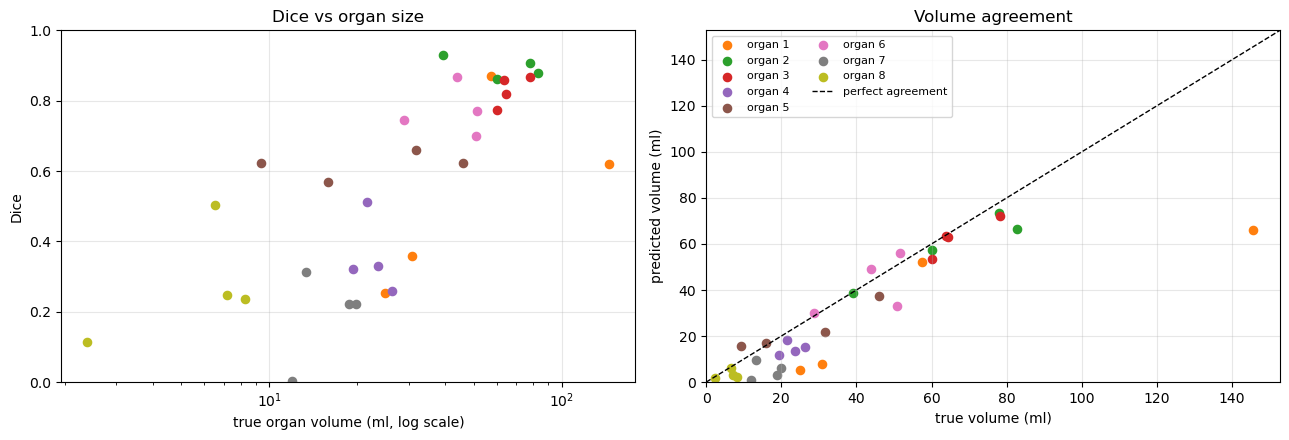

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for k, organ in ORGANS.items():
    r = results[results.organ == organ]
    axes[0].scatter(r["true ml"], r["Dice"], color=COLOURS[k], label=organ, s=35)
    axes[1].scatter(r["true ml"], r["pred ml"], color=COLOURS[k], label=organ, s=35)
axes[0].set_xscale("log"); axes[0].set_xlabel("true organ volume (ml, log scale)"); axes[0].set_ylabel("Dice")
axes[0].set_ylim(0, 1); axes[0].set_title("Dice vs organ size")
lim = [0, results[["true ml", "pred ml"]].max().max() * 1.05]
axes[1].plot(lim, lim, "k--", lw=1, label="perfect agreement")
axes[1].set_xlim(lim); axes[1].set_ylim(lim)
axes[1].set_xlabel("true volume (ml)"); axes[1].set_ylabel("predicted volume (ml)"); axes[1].set_title("Volume agreement")
axes[1].legend(fontsize=8, ncol=2)
for ax in axes: ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### 7c · Which classes get confused?
A **confusion matrix over voxels** (all test patients): row = true class, column = predicted class, normalised per row.
The diagonal is the fraction of each organ labelled correctly. Off-diagonal cells show *what* an organ is mistaken for: usually background (missed voxels at the boundary) or a neighbouring organ.

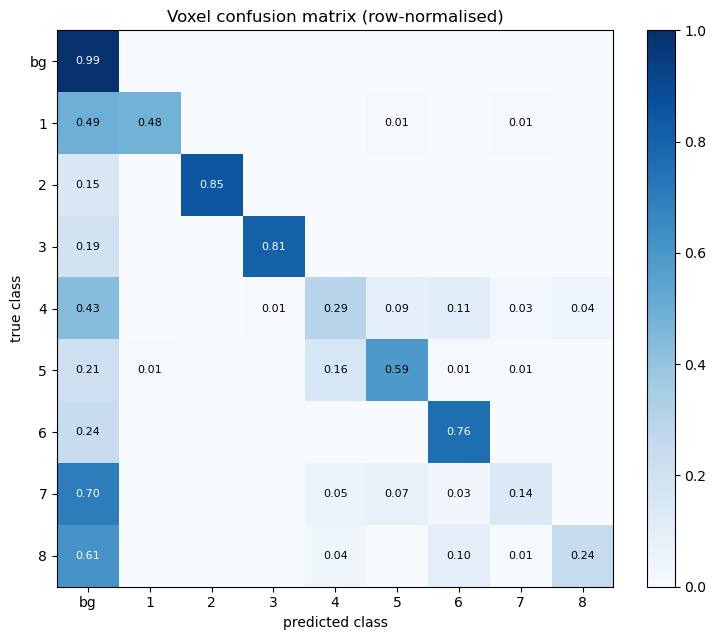

In [15]:
y_true = np.concatenate([c["lab"].ravel() for c in test_cases])
y_pred = np.concatenate([c["pred"].ravel() for c in test_cases])
cm = metrics.confusion_matrix(y_true, y_pred, labels=range(N_CLASSES), normalize="true")
names = ["bg"] + [o.replace("organ ", "") for o in ORGANS.values()]

fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
for i in range(N_CLASSES):
    for j in range(N_CLASSES):
        if cm[i, j] >= 0.005:
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if cm[i, j] > 0.6 else "black")
ax.set_xticks(range(N_CLASSES), names); ax.set_yticks(range(N_CLASSES), names)
ax.set_xlabel("predicted class"); ax.set_ylabel("true class"); ax.set_title("Voxel confusion matrix (row-normalised)")
plt.colorbar(im, ax=ax, fraction=0.046); plt.tight_layout(); plt.show()

### 7d · Look at the predictions
Numbers can hide problems, so always look. For each test patient: the axial, coronal and sagittal slices through the centre of the organs,
with ground truth (**solid**) and prediction (**dashed**) in each organ's colour, and the error map (pixels where prediction ≠ truth in red).

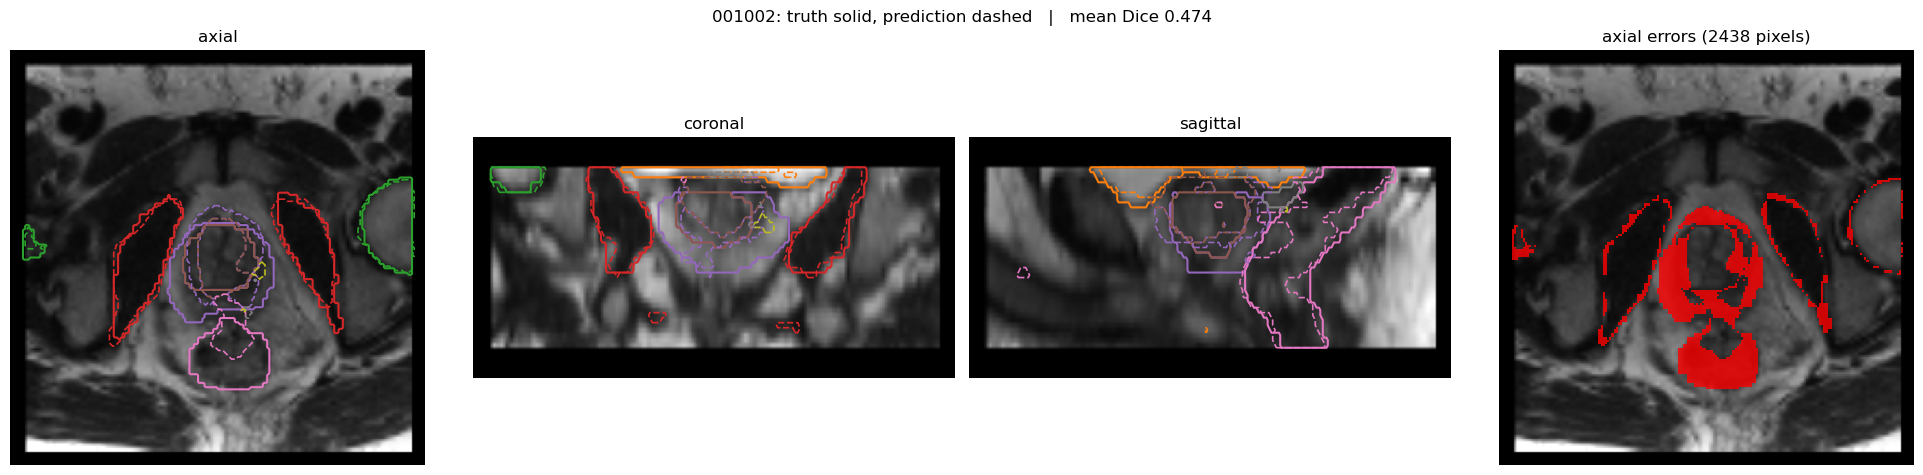

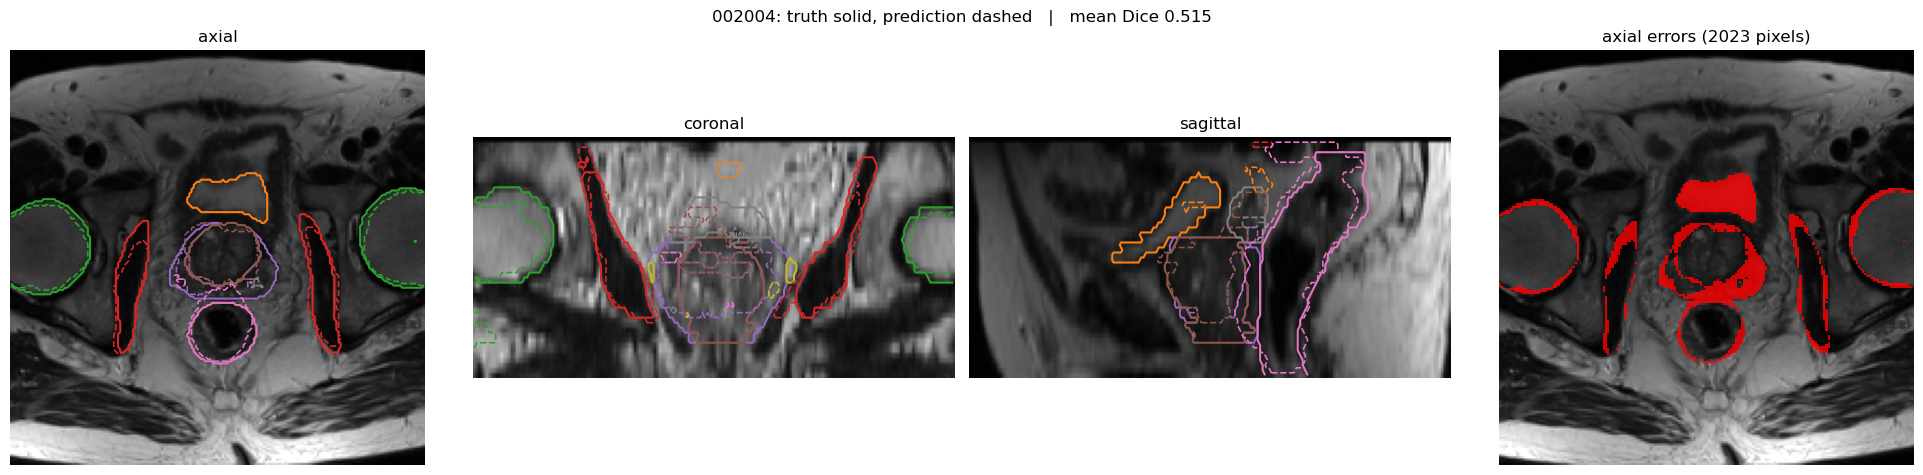

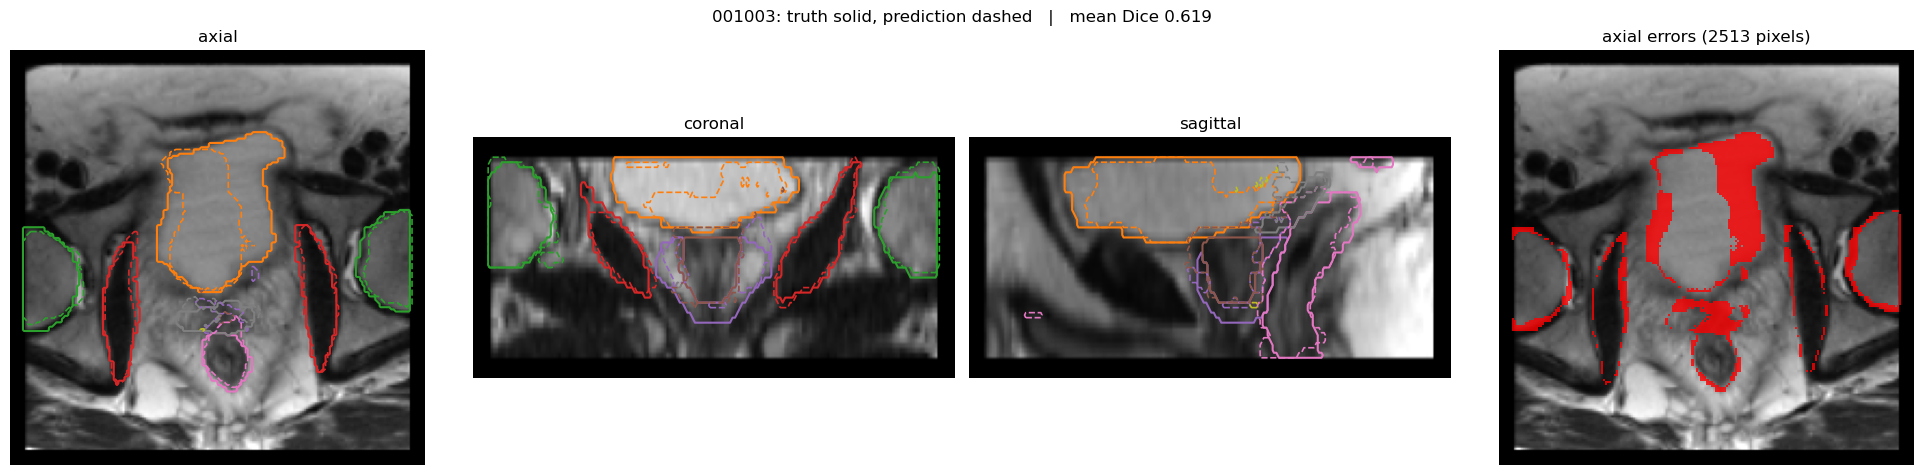

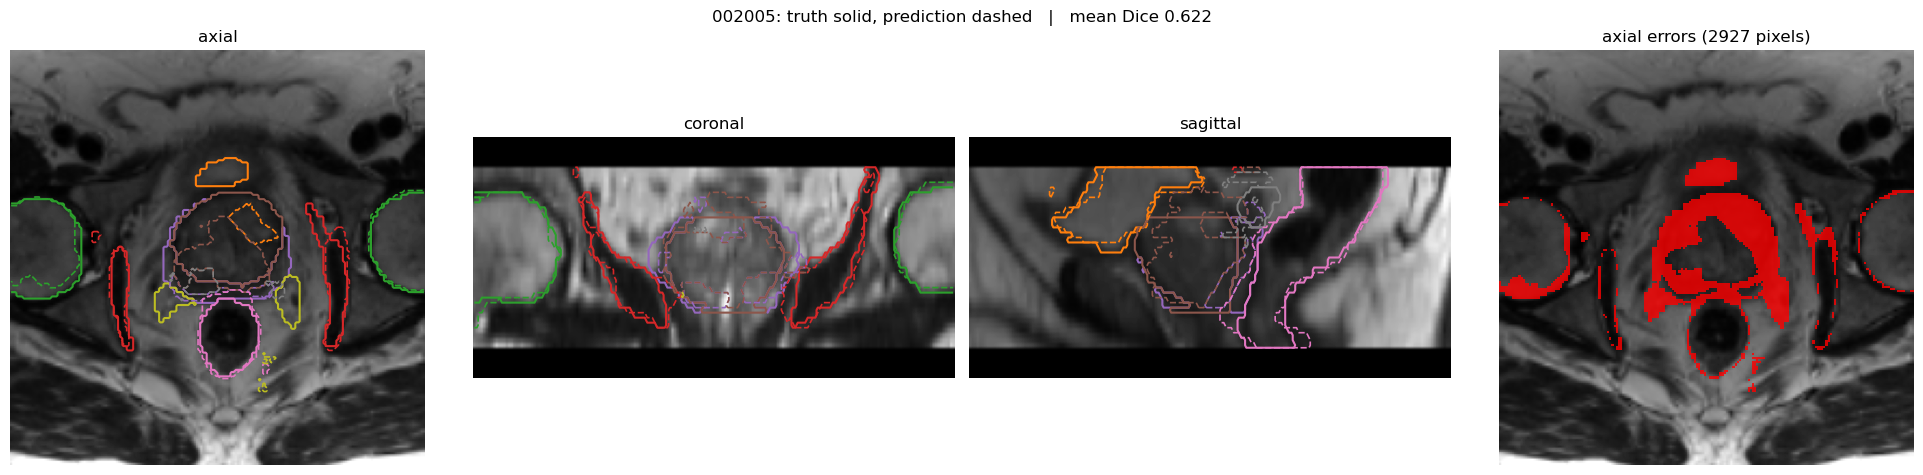

In [16]:
def show_case(c):
    z, y, x = np.round(np.argwhere(c["lab"] > 0).mean(axis=0)).astype(int)     # centre of all organs
    sz, sy, sx = SPACING_ZYX
    views = [("axial", np.s_[z], sy / sx, "upper"),
             ("coronal", np.s_[:, y], sz / sx, "lower"),
             ("sagittal", np.s_[:, :, x], sz / sy, "lower")]
    fig, axes = plt.subplots(1, 4, figsize=(20, 4.8), gridspec_kw={"width_ratios": [1, 1, 1, 1]})
    for ax, (name, sl, asp, org) in zip(axes, views):
        ax.imshow(c["img"][sl], cmap="gray", aspect=asp, origin=org)
        draw_labels(ax, c["lab"][sl], lw=1.5)
        draw_labels(ax, c["pred"][sl], lw=1.2, ls="--")
        ax.set_title(name); ax.axis("off")
    err = (c["pred"][z] != c["lab"][z])
    axes[3].imshow(c["img"][z], cmap="gray")
    axes[3].imshow(np.ma.masked_equal(err, 0), cmap="autumn", alpha=0.8, interpolation="nearest")
    axes[3].set_title(f"axial errors ({err.sum()} pixels)"); axes[3].axis("off")
    mean_dice = np.nanmean(list(per_organ_dice(c["pred"], c["lab"]).values()))
    fig.suptitle(f'{c["name"]}: truth solid, prediction dashed   |   mean Dice {mean_dice:.3f}')
    plt.tight_layout(); plt.show()

for c in test_cases:
    show_case(c)

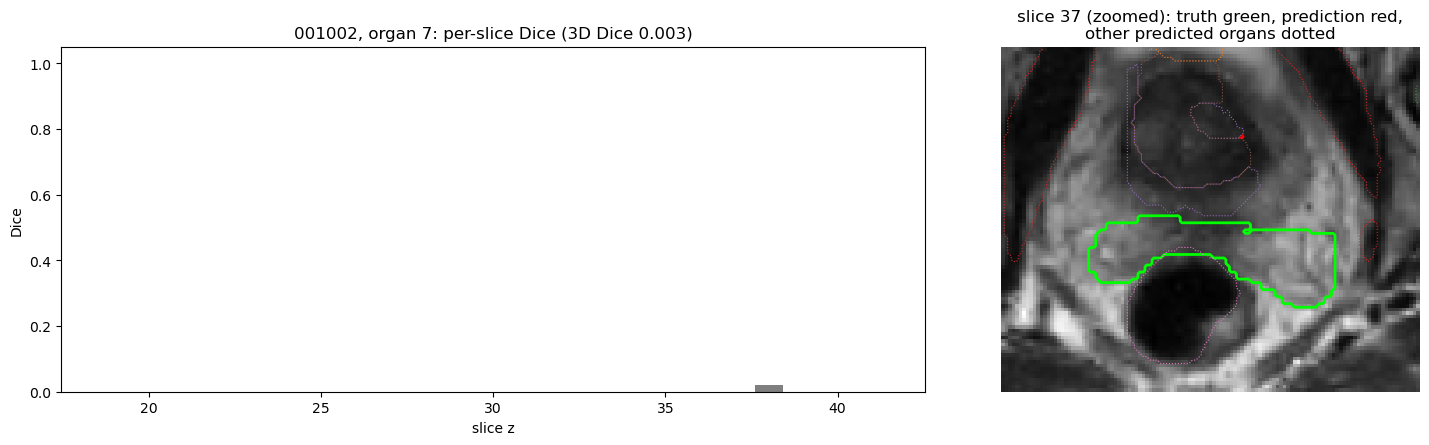

In [17]:
# The worst organ in the test set, slice by slice: where along z does it go wrong?
worst = results.loc[results["Dice"].idxmin()]
c = next(c for c in test_cases if c["name"] == worst["patient"])
k = next(k for k, o in ORGANS.items() if o == worst["organ"])
zs = [z for z in range(c["lab"].shape[0]) if (c["lab"][z] == k).any() or (c["pred"][z] == k).any()]
per_slice = [dice(c["pred"][z] == k, c["lab"][z] == k) for z in zs]
wrong = [((c["pred"][z] == k) != (c["lab"][z] == k)).sum() for z in zs]
z_bad = zs[int(np.argmax(wrong))]                                   # slice with the most wrong pixels for this organ
ys, xs = np.nonzero((c["lab"][z_bad] == k) | (c["pred"][z_bad] == k))
zoom = np.s_[max(ys.min() - 25, 0):ys.max() + 25, max(xs.min() - 25, 0):xs.max() + 25]   # crop around the organ

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1.6, 1]})
axes[0].bar(zs, per_slice, color=COLOURS[k])
axes[0].set_xlabel("slice z"); axes[0].set_ylabel("Dice"); axes[0].set_ylim(0, 1.05)
axes[0].set_title(f'{worst["patient"]}, {worst["organ"]}: per-slice Dice (3D Dice {worst["Dice"]:.3f})')
axes[1].imshow(c["img"][z_bad][zoom], cmap="gray")
if (c["lab"][z_bad] == k).any():
    axes[1].contour((c["lab"][z_bad] == k)[zoom], levels=[0.5], colors="lime", linewidths=2)
if (c["pred"][z_bad] == k).any():
    axes[1].contour((c["pred"][z_bad] == k)[zoom], levels=[0.5], colors="red", linestyles="--", linewidths=1.5)
draw_labels(axes[1], np.where(c["pred"][z_bad] != k, c["pred"][z_bad], 0)[zoom], lw=0.8, ls=":")   # what it predicted instead
axes[1].set_title(f"slice {z_bad} (zoomed): truth green, prediction red,\nother predicted organs dotted"); axes[1].axis("off")
plt.tight_layout(); plt.show()

The dotted contours show what the network predicted **instead** of the organ (compare with the confusion matrix in 7c).
Typical failure points: the **first and last slices** of an organ (partial volume, the organ is tiny there) and **boundaries with neighbouring organs** of similar intensity.
A 2D network never sees the slices above and below; a 2.5D or 3D network can use that context.

## 8 · Save predictions as NIfTI

`CopyInformation` copies spacing, origin and direction from the scan, so the prediction overlays exactly on it in ITK-SNAP or 3D Slicer.

In [18]:
pred_dir = OUT_DIR / "predictions"
pred_dir.mkdir(exist_ok=True)
for c in test_cases:
    out = sitk.GetImageFromArray(c["pred"])
    out.CopyInformation(c["sitk"])
    sitk.WriteImage(out, str(pred_dir / f'{c["name"]}_pred.nii.gz'))
print("saved:", sorted(p.name for p in pred_dir.iterdir()))

saved: ['001002_pred.nii.gz', '001003_pred.nii.gz', '002004_pred.nii.gz', '002005_pred.nii.gz']


## 9 · Exercises

1. **Loss.** Train with `DiceLoss` only and with `CrossEntropyLoss` only. Which organs gain or lose?
2. **Augmentation.** Remove the augmentation (`transform=None`). Compare the validation curves and test Dice.
3. **Capacity.** Try `channels=(8, 16, 32, 64, 128)` and `(32, 64, 128, 256, 512)`. Parameters, speed, Dice?
4. **Post-processing.** Keep the largest connected component of each organ. Which metric improves most? Why must you **not** do this for organ 2 (or other paired organs)?
5. **2.5D input.** Give the network 3 neighbouring slices as 3 input channels (`in_channels=3`). Do the first/last slices of each organ improve?
6. **Uncertainty.** With n = 4 test patients, how sure are you of the mean Dice? Bootstrap patients to get a 95% confidence interval.
7. **Cross-validation.** Rotate which 4 patients are the test set (5 folds) and report the mean over folds. How much does the result change between folds?